In [1]:
import numpy as np 
import pandas as pd  
import os
import matplotlib.pyplot as plt
import json
import random

In [2]:
L = 3*60/12 #steps for input window
H = 3*60/12 #steps for output winodw
L

15.0

In [3]:
#collecting all the mx files into one dataframe
m_x_files = []
avlength = 0
minlength = float("inf")
maxlength =  0
len(m_x_files)

0

In [ ]:

def collect_m_x(folder: str):
    global avlength
    global minlength 
    global maxlength
    for fname in os.listdir(folder):
        if fname.endswith(".csv"):
            path = os.path.join(folder, fname)
            df = pd.read_csv(path,sep="\t")
            # check if file has any M or X flare
            if (df["MFLARE"].sum() > 0) or (df["XFLARE"].sum() > 0):
                m_x_files.append(path)
                avlength = avlength+ len(df)
                if (len(df) > maxlength):
                    maxlength = len(df)
                if (len(df))< minlength:
                    minlength = len(df)

collect_m_x("/kaggle/input/partition1-swanrafal-et-al/partition1")
collect_m_x("/kaggle/input/partition2-swanrafal-et-al/partition2")
collect_m_x("/kaggle/input/partition3-swanrafal-et-al/partition3")
collect_m_x("/kaggle/input/partition4-swanrafal-et-al/partition4")
collect_m_x("/kaggle/input/partition5-swanrafal-et-al/partition5")

print(f"Found {len(m_x_files)} files with ≥M1.0 flares. Expected length is 191.")

#saving into a csv
mxdf = pd.DataFrame(m_x_files)
mxdf.to_csv('m_x_files_p1to5.csv', index=False)


In [10]:
print("average hours of each m-x file: " + str((avlength/len(m_x_files))*12/60))
print("min hours of each m-x file: " + str(minlength*12/60))
print("max hours of each m-x file: " + str(maxlength*12/60))

average hours of each m-x file: 307.6973821989529
min hours of each m-x file: 62.8
max hours of each m-x file: 425.2


In [7]:
#collects xflare instance with time stamps
def collect_mxflare_instances_arrays(path_list, inputwindow=15, feature_cols=None, label_col="XFLARE", classif = 1):
    rows = []  # will hold dicts with "input" and "output"
    
    for path in path_list:
        try:
            df = pd.read_csv(path, sep="\t")
        except Exception:
            df = pd.read_csv(path)

        if "Timestamp" in df.columns:
            df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors="coerce")

        if label_col not in df.columns:
            continue

        flare_indices = df.index[df[label_col] > 0].tolist()
        
        for idx in flare_indices:
            start = max(0, idx - inputwindow)

            inputinstance = df.iloc[start:idx].copy()
            
            # --- Input section ---
            if feature_cols is None:
                # if no columns defined, only take the xr flux
                feats = inputinstance[:]
            else:
                feats = inputinstance[feature_cols]
            
            # ensure exactly "window" timesteps (pad with NaN if short)
            if len(feats) < inputwindow:
                pad = pd.DataFrame(np.nan, index=range(inputwindow - len(feats)), columns=feats.columns)
                feats = pd.concat([feats, pad], ignore_index=True)
            else:
                feats = feats.iloc[:inputwindow]
            
            
            # store one row with input/output
            rows.append({
                "input": feats.to_numpy(),   # shape (window, 5)
                "output": classif # shape (1)
            })
    
    return pd.DataFrame(rows)

In [16]:
m_x_files_opened.iloc[0][0]

/tmp/ipykernel_47/2486900430.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  m_x_files_opened.iloc[0][0]


'/kaggle/input/partition1-swanrafal-et-al/partition1/753.csv'

In [22]:
testopen = pd.read_csv(m_x_files_opened.iloc[0][0], sep="\t")
testopen.columns

/tmp/ipykernel_47/3321930128.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  testopen = pd.read_csv(m_x_files_opened.iloc[0][0], sep="\t")


Index(['Timestamp', 'TOTUSJH', 'TOTBSQ', 'TOTPOT', 'TOTUSJZ', 'ABSNJZH',
       'SAVNCPP', 'USFLUX', 'TOTFZ', 'MEANPOT', 'EPSZ', 'MEANSHR', 'SHRGT45',
       'MEANGAM', 'MEANGBT', 'MEANGBZ', 'MEANGBH', 'MEANJZH', 'TOTFY',
       'MEANJZD', 'MEANALP', 'TOTFX', 'EPSY', 'EPSX', 'R_VALUE', 'CRVAL1',
       'CRLN_OBS', 'CRLT_OBS', 'CRVAL2', 'HC_ANGLE', 'SPEI', 'LAT_MIN',
       'LON_MIN', 'LAT_MAX', 'LON_MAX', 'QUALITY', 'BFLARE', 'BFLARE_LABEL',
       'CFLARE', 'CFLARE_LABEL', 'MFLARE', 'MFLARE_LABEL', 'XFLARE',
       'XFLARE_LABEL', 'BFLARE_LOC', 'BFLARE_LABEL_LOC', 'CFLARE_LOC',
       'CFLARE_LABEL_LOC', 'MFLARE_LOC', 'MFLARE_LABEL_LOC', 'XFLARE_LOC',
       'XFLARE_LABEL_LOC', 'XR_MAX', 'XR_QUAL', 'IS_TMFI'],
      dtype='object')

In [23]:
#collecting the phase 1 stuff
m_x_files_opened = pd.read_csv("/kaggle/input/m-x-files/m_x_files_p1to5.csv")
path_list = m_x_files_opened.iloc[:, 0].tolist()
xflareinstances = collect_mxflare_instances_arrays(path_list, feature_cols=['TOTUSJH', 'TOTBSQ', 'TOTPOT', 'TOTUSJZ', 'ABSNJZH', 'SAVNCPP', 'USFLUX', 'TOTFZ', 'MEANPOT', 'EPSZ', 'MEANSHR', 'SHRGT45', 'MEANGAM', 'MEANGBT', 'MEANGBZ', 'MEANGBH', 'MEANJZH', 'TOTFY', 'MEANJZD', 'MEANALP', 'TOTFX', 'EPSY', 'EPSX', 'R_VALUE', "XR_MAX","XR_QUAL", "IS_TMFI"], label_col="XFLARE", classif = 2)
mflareinstances = collect_mxflare_instances_arrays(path_list, feature_cols=['TOTUSJH', 'TOTBSQ', 'TOTPOT', 'TOTUSJZ', 'ABSNJZH', 'SAVNCPP', 'USFLUX', 'TOTFZ', 'MEANPOT', 'EPSZ', 'MEANSHR', 'SHRGT45', 'MEANGAM', 'MEANGBT', 'MEANGBZ', 'MEANGBH', 'MEANJZH', 'TOTFY', 'MEANJZD', 'MEANALP', 'TOTFX', 'EPSY', 'EPSX', 'R_VALUE', "XR_MAX","XR_QUAL", "IS_TMFI"], label_col="MFLARE", classif = 1)
print("xflare len: " + str(len(xflareinstances)))
print("mflare len: " + str(len(mflareinstances)))

xflare len: 47
mflare len: 703


In [24]:
#collects xflare instance with time stamps
def collect_extramxflare_instances_arrays(path_list, inputwindow=15, outputwindow = 15, feature_cols=None, label_col="XFLARE", classif = 1):
    rows = []  # will hold dicts with "input" and "output"
    
    for path in path_list:
        try:
            df = pd.read_csv(path, sep="\t")
        except Exception:
            df = pd.read_csv(path)

        if "Timestamp" in df.columns:
            df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors="coerce")

        if label_col not in df.columns:
            continue

        flare_indices = df.index[df[label_col] > 0].tolist()
        
        for idx in flare_indices:
            start = max(0, idx - inputwindow-outputwindow)
            for i in range(start, idx-inputwindow, 2):
                inputinstance = df.iloc[i:i+inputwindow].copy()
            
                # --- Input section ---
                if feature_cols is None:
                    # if no columns defined, only take the xr flux
                    feats = inputinstance[:]
                else:
                    feats = inputinstance[feature_cols]
                
                # ensure exactly "window" timesteps (pad with NaN if short)
                if len(feats) < inputwindow:
                    pad = pd.DataFrame(np.nan, index=range(inputwindow - len(feats)), columns=feats.columns)
                    feats = pd.concat([feats, pad], ignore_index=True)
                else:
                    feats = feats.iloc[:inputwindow]
                
                
                # store one row with input/output
                rows.append({
                    "input": feats.to_numpy(),   # shape (window, 5)
                    "output": classif # shape (1)
                })
    
    return pd.DataFrame(rows)

In [25]:
m_x_files_opened = pd.read_csv("/kaggle/input/m-x-files/m_x_files_p1to5.csv")
path_list = m_x_files_opened.iloc[:, 0].tolist()
exxflareinstances = collect_extramxflare_instances_arrays(path_list, feature_cols=['TOTUSJH', 'TOTBSQ', 'TOTPOT', 'TOTUSJZ', 'ABSNJZH', 'SAVNCPP', 'USFLUX', 'TOTFZ', 'MEANPOT', 'EPSZ', 'MEANSHR', 'SHRGT45', 'MEANGAM', 'MEANGBT', 'MEANGBZ', 'MEANGBH', 'MEANJZH', 'TOTFY', 'MEANJZD', 'MEANALP', 'TOTFX', 'EPSY', 'EPSX', 'R_VALUE', "XR_MAX","XR_QUAL", "IS_TMFI"], label_col="XFLARE", classif = 2)
exmflareinstances = collect_extramxflare_instances_arrays(path_list, feature_cols=['TOTUSJH', 'TOTBSQ', 'TOTPOT', 'TOTUSJZ', 'ABSNJZH', 'SAVNCPP', 'USFLUX', 'TOTFZ', 'MEANPOT', 'EPSZ', 'MEANSHR', 'SHRGT45', 'MEANGAM', 'MEANGBT', 'MEANGBZ', 'MEANGBH', 'MEANJZH', 'TOTFY', 'MEANJZD', 'MEANALP', 'TOTFX', 'EPSY', 'EPSX', 'R_VALUE', "XR_MAX","XR_QUAL", "IS_TMFI"], label_col="MFLARE", classif = 1)
print("xflare len: " + str(len(exxflareinstances)))
print("mflare len: " + str(len(exmflareinstances)))

xflare len: 376
mflare len: 5539


In [26]:
flaringdata = pd.concat([xflareinstances, mflareinstances, exxflareinstances, exmflareinstances], axis=0)
flaringdata  

,input,output
0,"[[3001.985855845332, 42032630217.897705, 7.537...",2
1,"[[3060.1599758104085, 39483269823.43112, 8.583...",2
2,"[[5418.387235375029, 100236576378.8792, 1.9000...",2
3,"[[3477.8527521636406, 47997404067.1488, 1.0569...",2
4,"[[3979.373543466456, 61606571606.5923, 1.10836...",2
...,...,...
5534,"[[3501.7027878522526, 67590696251.2114, 1.1115...",1
5535,"[[3511.075688904852, 68294828707.573, 1.130324...",1
5536,"[[3550.6427485311115, 68997483014.85353, 1.138...",1
5537,"[[3609.773555066449, 69412955366.5683, 1.16052...",1


In [27]:
nonflaring_files = []

In [28]:
#function to collect nonflares
def collect_nonflares(folder: str):

    for fname in os.listdir(folder):
        if fname.endswith(".csv"):
            path = os.path.join(folder, fname)
            df = pd.read_csv(path,sep="\t")
            # check if file has any M or X flare
            if (df["MFLARE"].sum() == 0) and (df["XFLARE"].sum() == 0):
                nonflaring_files.append(path)

collect_nonflares("/kaggle/input/partition1-swanrafal-et-al/partition1")
collect_nonflares("/kaggle/input/partition2-swanrafal-et-al/partition2")
collect_nonflares("/kaggle/input/partition3-swanrafal-et-al/partition3")
collect_nonflares("/kaggle/input/partition4-swanrafal-et-al/partition4")
collect_nonflares("/kaggle/input/partition5-swanrafal-et-al/partition5")

print(f"Found {len(nonflaring_files)} files with <M1.0 flares. Expected length is 3907.")

#saving into a csv
nonflaresdf = pd.DataFrame(nonflaring_files)
nonflaresdf.to_csv('nonflares_files_p1to5.csv', index=False)
len(nonflaresdf)

Found 3907 files with <M1.0 flares. Expected length is 3907.


3907

In [29]:
#collects nonflare instance with time stamps
def collect_nonflares_instances_arrays(path_list, inputwindow=15, feature_cols=None, classif = 0, num_samples_per_file = 3):
    rows = []  # will hold dicts with "input" and "output"
    
    for path in path_list:
        try:
            df = pd.read_csv(path, sep="\t")
        except Exception:
            df = pd.read_csv(path)

        if "Timestamp" in df.columns:
            df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors="coerce")
        
        max_start = len(df) - inputwindow
        if max_start <= 0:
            continue
        used_starts = set()

        for _ in range(num_samples_per_file):
            # try up to maybe 50 times to find a unique window
            tries = 0
            while tries < 50:
                start = random.randint(0, max_start)
                if start not in used_starts:
                    used_starts.add(start)
                    break
                tries += 1
            
            if tries == 50:
                continue   # could not find a new index
            
            # now process this unique start index
            inputinstance = df.iloc[start:start+inputwindow].copy()
            
            # --- Input section ---
            if feature_cols is None:
                # if no columns defined, only take the xr flux
                feats = inputinstance[:]
            else:
                feats = inputinstance[feature_cols]
            
            # ensure exactly "window" timesteps (pad with NaN if short)
            if len(feats) < inputwindow:
                pad = pd.DataFrame(np.nan, index=range(inputwindow - len(feats)), columns=feats.columns)
                feats = pd.concat([feats, pad], ignore_index=True)
            else:
                feats = feats.iloc[:inputwindow]
            
            
            # store one row with input/output
            rows.append({
                "input": feats.to_numpy(),   # shape (window, 5)
                "output": 0 # shape (1)
            })
    
    return pd.DataFrame(rows)

In [54]:
nonflares_files_opened = pd.read_csv("/kaggle/working/nonflares_files_p1to5.csv")
nonpath_list = nonflares_files_opened.iloc[:, 0].tolist()
nonflareinstances = collect_nonflares_instances_arrays(nonpath_list, feature_cols=['TOTUSJH', 'TOTBSQ', 'TOTPOT', 'TOTUSJZ', 'ABSNJZH', 'SAVNCPP', 'USFLUX', 'TOTFZ', 'MEANPOT', 'EPSZ', 'MEANSHR', 'SHRGT45', 'MEANGAM', 'MEANGBT', 'MEANGBZ', 'MEANGBH', 'MEANJZH', 'TOTFY', 'MEANJZD', 'MEANALP', 'TOTFX', 'EPSY', 'EPSX', 'R_VALUE', "XR_MAX","XR_QUAL", "IS_TMFI"], classif = 0)
print("nonflaring len: " + str(len(nonflareinstances)))

/tmp/ipykernel_47/3601182176.py:12: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors="coerce")
/tmp/ipykernel_47/3601182176.py:12: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors="coerce")


nonflaring len: 11602


In [31]:
#applicable for both x and m flares
def flareinstancesprocessing(df, tmfi_input_idx, xrqual_input_idx, xrqual_threshold=6):
    out = df.copy()

    def _to_dt(a):
        if isinstance(a, np.ndarray):
            return pd.to_datetime(a, errors="coerce").to_numpy(dtype="datetime64[ns]")
        return a

    if "Timestamp" in out.columns:
        out["Timestamp"] = out["Timestamp"].apply(_to_dt)


    # ----------------------------------------------------
    # 1. Remove any rows where input contains ANY NaN
    # ----------------------------------------------------
    def has_nan(arr):
        arr = np.asarray(arr, dtype=float)
        return np.isnan(arr).any()

    mask_no_nan = out["input"].apply(lambda arr: not has_nan(arr))
    out = out[mask_no_nan].reset_index(drop=True)
    # drop rows where TMFI is not equal to true
    mask_tmfi = out["input"].apply(
        lambda arr: not np.any((arr[:, tmfi_input_idx] != 1))
    )
    out = out[mask_tmfi].reset_index(drop=True)

    # drop rows where XR_QUAL < threshold (doesn't check for NAN)
    mask_qual = out["input"].apply(
        lambda arr: not np.any((arr[:, xrqual_input_idx] < xrqual_threshold))
    )
    out = out[mask_qual].reset_index(drop=True)

    return out

Good flare indicators: unsigned current density, unsigned flux, and current helicity

“some studies have shown that the magnetic twist parameter does not perform well for classification whereas earlier physics-based works suggest that twist is a flare-relevant parameter”
Regenerated 6 twist-like features to add to data! (TOTABSTWIST was found to be most useful)

https://agupubs.onlinelibrary.wiley.com/doi/epdf/10.1029/2019SW002214: 
First, the most valuable parameters for prediction in our study, SAVNCPP andTOTUSJH, are scalar values representing integrals of electric current and current helicity, respectively

#unsigned current density, unsigned flux, and current helicity
#Flare rates correlates with feature of maximum horizontal gradient of the longitudinal magnetic field 
#- vorticity and magnetic flux corresponds to different levels of flares
#weighted horizontal magnetic gradient (WGM) is strongly correlated with flare events through time-series
#Polarity inversion line is an important factor
#Including historical flare rate as a forecasting factor can improve performance greatly
# - Ex. how many flares occurred in the last x hours
#- Not as useful if you’re trying to create a real-time flare forecasting system (most flare catalogs are delayed before they are released)


In [55]:
fulldata = pd.concat([nonflareinstances, flaringdata], axis=0)
#cleaning the full dataset
cleanedfulldata = flareinstancesprocessing(fulldata, -1, -2)
cleanedfulldata

,input,output
0,"[[126.48770499867778, 1410815997.755, 9.325572...",0
1,"[[132.23430683900958, 1436767014.9759, 9.33811...",0
2,"[[134.19263217963208, 1515273622.7441, 9.52698...",0
3,"[[18.72243701249855, 149696538.2784, 1.1229188...",0
4,"[[42.65811044771085, 277685597.68340003, 1.740...",0
...,...,...
7971,"[[2493.097504024852, 35291361469.0244, 3.84721...",1
7972,"[[2485.71216269864, 35322778493.224594, 3.8200...",1
7973,"[[2451.8404410913613, 35231337976.9912, 3.8331...",1
7974,"[[2422.4141668407588, 35063170756.2088, 3.8016...",1


In [56]:
print("number of positive samples: " + str(len(cleanedfulldata[cleanedfulldata["output"] == 2])+len(cleanedfulldata[cleanedfulldata["output"] == 1])))     
print("number of m samples: " + str(len(cleanedfulldata[cleanedfulldata["output"] == 1])))
print("number of x samples: " + str(len(cleanedfulldata[cleanedfulldata["output"] == 2])))     
print("number of nonflaring samples: " + str(len(cleanedfulldata[cleanedfulldata["output"] == 0])))

number of positive samples: 3063
number of m samples: 2882
number of x samples: 181
number of nonflaring samples: 4913


In [59]:
X = np.stack(cleanedfulldata["input"].to_numpy())
print(np.any(X < 0))
print(len(X<0))

True
7976


In [61]:
X.shape # (N, T, F+2)

(7976, 15, 27)

In [62]:
#finding which indices are negative
neg_feature_mask = np.any(X < 0, axis=(0, 1))
neg_feature_indices = np.where(neg_feature_mask)[0]
neg_feature_indices

array([ 7,  9, 16, 17, 18, 19, 20, 21, 22])

In [63]:
df_to_save = cleanedfulldata.copy()
df_to_save["input"] = df_to_save["input"].apply(lambda x: json.dumps(x.tolist()))
df_to_save["output"] = df_to_save["output"].astype(int)
df_to_save.to_csv("cleanedfulldata_withrand_25COL.csv", index=False)

In [3]:
#FOR CSV
# re opening the xflare instances time series collection files
full_reloaded = pd.read_csv("/kaggle/input/fulldata-withnan/cleanedfulldata_withrand_25COL.csv")
full_reloaded["input"] = full_reloaded["input"].apply(lambda x: np.array(json.loads(x)))
full_reloaded["output"] = full_reloaded["output"]
full_reloaded

,input,output
0,"[[1.8711366563714084e+21, 174.46532973091027, ...",0
1,"[[1.9044814855400368e+20, 12.47472780229666, 9...",0
2,"[[1.6218363769320474e+21, 117.20903173356837, ...",0
3,"[[1.7956128243739378e+20, 8.52167773695303, 68...",0
4,"[[1.304222021381758e+21, 77.77326029461855, 58...",0
...,...,...
8025,"[[4.759091683094668e+22, 2493.097504024852, 35...",1
8026,"[[4.774497109077395e+22, 2485.71216269864, 353...",1
8027,"[[4.754332187070513e+22, 2451.8404410913613, 3...",1
8028,"[[4.714557192732773e+22, 2422.4141668407588, 3...",1


In [7]:
df_to_save = cleanedfullnonnandata.copy()
df_to_save["input"] = df_to_save["input"].apply(lambda x: json.dumps(x.tolist()))
df_to_save["output"] = df_to_save["output"].astype(int)
df_to_save.to_csv("cleanedfullNONNANdata_withrand_FULLCOL.csv", index=False)

In [75]:
def datvisualization(flaring_df, nonflaring_df, feature_idx, featurename, L):
    """
    flaring_df:     DataFrame with columns ["input", "output"], output=1
    nonflaring_df:  same, but output=0
    feature_idx:    which feature column in the (L, F) array to visualize (0-based)
    L:              input window length (number of timesteps)
    """

    # safety check
    if L != 15:
        print("CHANGE THE TIME SERIES NOW!!!! IT IS NOT CHANGEDDDDD")

    # extract this feature across all samples
    # each element of "input" is shape (L, F). We take [:, feature_idx]
    flare_feat = np.stack([arr[:, feature_idx] for arr in flaring_df["input"]])
    nonflare_feat = np.stack([arr[:, feature_idx] for arr in nonflaring_df["input"]])

    # flare stats
    flare_mean = flare_feat.mean(axis=0)   # shape (L,)
    flare_std  = flare_feat.std(axis=0)

    # nonflare stats
    nonflare_mean = nonflare_feat.mean(axis=0)
    nonflare_std  = nonflare_feat.std(axis=0)

    # x-axis: timesteps (1..L) or (0..L-1), your choice
    t = np.arange(1, L+1)

    plt.figure(figsize=(8,5))

    # flaring class
    plt.plot(t, flare_mean, label="Flare mean")
    plt.fill_between(t, flare_mean - flare_std, flare_mean + flare_std,
                     alpha=0.2)

    # nonflaring class
    plt.plot(t, nonflare_mean, label="Non-flare mean")
    plt.fill_between(t, nonflare_mean - nonflare_std, nonflare_mean + nonflare_std,
                     alpha=0.2)

    plt.xlabel("Timestep (12-minute intervals)")
    plt.ylabel(featurename + " value")  # or a real name if you have one
    plt.title(featurename+": Flare vs Non-flare (mean ± std)")
    plt.legend()
    plt.tight_layout()
    plt.show()


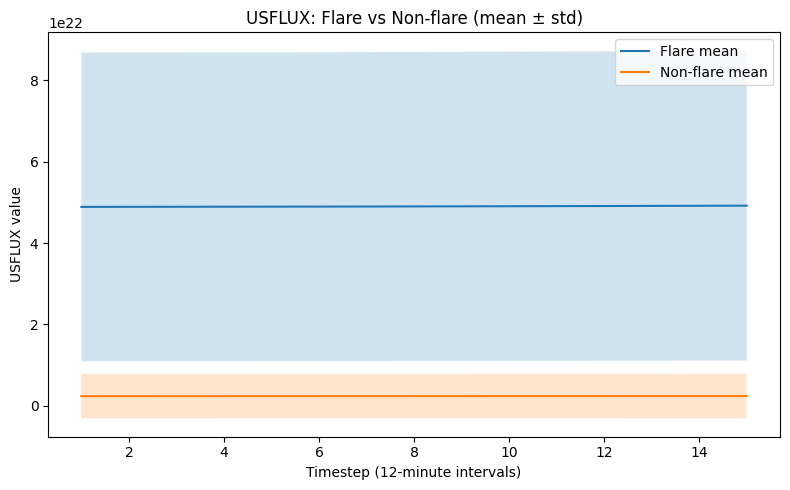

In [77]:
flaring_df = full_reloaded[full_reloaded["output"] != 0]      # or 2/3 if those are flare classes
nonflaring_df = full_reloaded[full_reloaded["output"] == 0]
#"USFLUX", "TOTUSJH", "TOTBSQ", "MEANPOT", "R_VALUE", "XR_MAX","XR_QUAL", "IS_TMFI"
datvisualization(flaring_df, nonflaring_df, feature_idx=0, featurename = "USFLUX", L=L)

In [72]:
flaring_df["input"].iloc[0]

array([[2.65629950e+22, 3.06015998e+03, 3.94832698e+10, 1.56183044e+04,
        4.78072517e+00, 7.22040000e-07, 1.20000000e+01, 1.00000000e+00],
       [2.66138217e+22, 3.07865817e+03, 3.95176354e+10, 1.55797002e+04,
        4.76129869e+00, 5.37150000e-07, 1.20000000e+01, 1.00000000e+00],
       [2.67204947e+22, 3.09610940e+03, 3.95568802e+10, 1.54855853e+04,
        4.74246087e+00, 8.77180000e-07, 1.20000000e+01, 1.00000000e+00],
       [2.67942023e+22, 3.13059940e+03, 3.95860273e+10, 1.55636109e+04,
        4.76913350e+00, 1.24260000e-06, 1.20000000e+01, 1.00000000e+00],
       [2.67182716e+22, 3.13704821e+03, 3.96608405e+10, 1.57582439e+04,
        4.77552142e+00, 1.26410000e-06, 1.20000000e+01, 1.00000000e+00],
       [2.66459342e+22, 3.13143783e+03, 3.96416101e+10, 1.58373149e+04,
        4.75919581e+00, 2.70220000e-06, 1.20000000e+01, 1.00000000e+00],
       [2.66985692e+22, 3.15699557e+03, 3.95862108e+10, 1.56790824e+04,
        4.79443233e+00, 2.23260000e-06, 1.20000000e+01, 1.